# Superstore Sales Analysis and Business Intelligence Dashboard
## Project Objective
The Objective of this projject is to analyze retails sales data using Python to indetify sales trends,product performance ,regional differences,and profitability patterns ,The findings will support data-driven business recommendations and a Power BI dashborad.
## Tools and Technologies
-Python   
-Pandas and Numpy    
-Malplotlib and seaborn     
-Power BI    
-Git and Github  

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
sns.set_theme(style='whitegrid')
print('Libraries imported successfully')

Libraries imported successfully


In [3]:
# Load he csv file
df=pd.read_csv('../data/SampleSuperstore.csv')

In [4]:
#Inspect the data
print(df.shape)


(9994, 13)


In [5]:
print(df.columns)


Index(['Ship Mode', 'Segment', 'Country', 'City', 'State', 'Postal Code',
       'Region', 'Category', 'Sub-Category', 'Sales', 'Quantity', 'Discount',
       'Profit'],
      dtype='object')


In [6]:
display(df.head())

,Ship Mode,Segment,Country,City,State,Postal Code,Region,Category,Sub-Category,Sales,Quantity,Discount,Profit
0,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Bookcases,261.9600,2,0.00,41.9136
1,Second Class,Consumer,United States,Henderson,Kentucky,42420,South,Furniture,Chairs,731.9400,3,0.00,219.5820
2,Second Class,Corporate,United States,Los Angeles,California,90036,West,Office Supplies,Labels,14.6200,2,0.00,6.8714
3,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Furniture,Tables,957.5775,5,0.45,-383.0310
4,Standard Class,Consumer,United States,Fort Lauderdale,Florida,33311,South,Office Supplies,Storage,22.3680,2,0.20,2.5164


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 13 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Ship Mode     9994 non-null   object 
 1   Segment       9994 non-null   object 
 2   Country       9994 non-null   object 
 3   City          9994 non-null   object 
 4   State         9994 non-null   object 
 5   Postal Code   9994 non-null   int64  
 6   Region        9994 non-null   object 
 7   Category      9994 non-null   object 
 8   Sub-Category  9994 non-null   object 
 9   Sales         9994 non-null   float64
 10  Quantity      9994 non-null   int64  
 11  Discount      9994 non-null   float64
 12  Profit        9994 non-null   float64
dtypes: float64(3), int64(2), object(8)
memory usage: 1015.1+ KB


In [8]:
#check missing values and duplicates
print(df.isnull().sum())


Ship Mode       0
Segment         0
Country         0
City            0
State           0
Postal Code     0
Region          0
Category        0
Sub-Category    0
Sales           0
Quantity        0
Discount        0
Profit          0
dtype: int64


In [9]:
print("Duplicate rows : ",df.duplicated().sum())

Duplicate rows :  17


In [10]:
print(df.dtypes)

Ship Mode        object
Segment          object
Country          object
City             object
State            object
Postal Code       int64
Region           object
Category         object
Sub-Category     object
Sales           float64
Quantity          int64
Discount        float64
Profit          float64
dtype: object


In [11]:
print('Duplicates before : ',df.duplicated().sum())
df=df.drop_duplicates() # remove exact duplicate rows
print('Duplicates after : ',df.duplicated().sum())

Duplicates before :  17
Duplicates after :  0


In [12]:
#Handles missing values
print(df.isnull().sum().sum())

0


In [13]:
df.columns.tolist()

['Ship Mode',
 'Segment',
 'Country',
 'City',
 'State',
 'Postal Code',
 'Region',
 'Category',
 'Sub-Category',
 'Sales',
 'Quantity',
 'Discount',
 'Profit']

In [14]:
#Correct  Column datatype 
print(df.dtypes)

Ship Mode        object
Segment          object
Country          object
City             object
State            object
Postal Code       int64
Region           object
Category         object
Sub-Category     object
Sales           float64
Quantity          int64
Discount        float64
Profit          float64
dtype: object


In [15]:
numeric_cols=['Postal Code','Sales','Quantity','Discount','Profit']
for col in numeric_cols:
    df[col] =pd.to_numeric(df[col],errors='coerce')
print("Updated data types : ")
print(df[numeric_cols].dtypes)

Updated data types : 
Postal Code      int64
Sales          float64
Quantity         int64
Discount       float64
Profit         float64
dtype: object


## Save the cleaned dataset

In [16]:
Path('../data/Processed').mkdir(parents=True,exist_ok=True)
df.to_csv('../data/processed/cleaned_superstore.csv',index=False)
print('Cleaned dataset saved sucessfully')

Cleaned dataset saved sucessfully


# EDA

In [17]:
#Understand the numeric data
df[['Postal Code','Sales','Quantity','Discount','Profit']].describe()

,Postal Code,Sales,Quantity,Discount,Profit
count,9977.000000,9977.000000,9977.000000,9977.000000,9977.00000
mean,55154.964117,230.148902,3.790719,0.156278,28.69013
std,32058.266816,623.721409,2.226657,0.206455,234.45784
min,1040.000000,0.444000,1.000000,0.000000,-6599.97800
25%,23223.000000,17.300000,2.000000,0.000000,1.72620
50%,55901.000000,54.816000,3.000000,0.200000,8.67100
75%,90008.000000,209.970000,5.000000,0.200000,29.37200
max,99301.000000,22638.480000,14.000000,0.800000,8399.97600


In [18]:
#find total sales and profits
total_sales=df['Sales'].sum()
total_profit=df['Profit'].sum()
total_quantity=df['Quantity'].sum()

print(f'Total Sales : ${total_sales:,.2f}')
print(f'Total profit : ${total_profit:,.2f}')
print(f'Total Quantity : ${total_quantity:,.2f}')


Total Sales : $2,296,195.59
Total profit : $286,241.42
Total Quantity : $37,820.00


## Analyze the Sales by Category

In [19]:
#Analyze sales by category
category_sales=df.groupby('Category')['Sales'].sum().sort_values(ascending=False)
print(category_sales)

Category
Technology         836154.0330
Furniture          741306.3133
Office Supplies    718735.2440
Name: Sales, dtype: float64


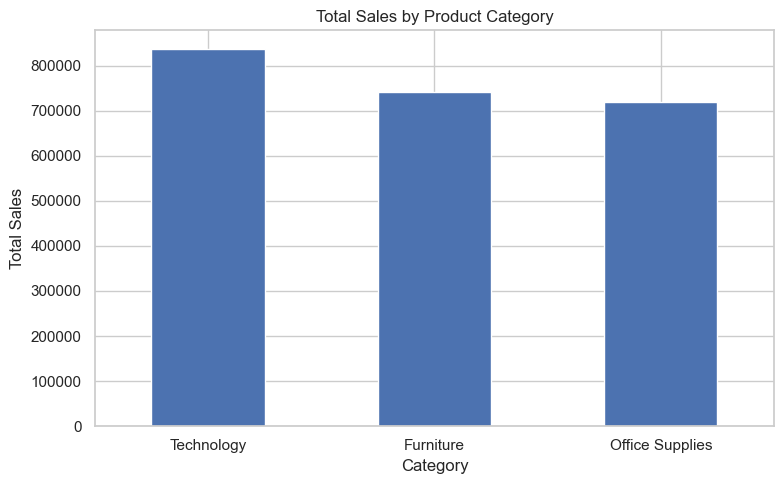

In [20]:
#Visualize the result
category_sales.plot(kind="bar",figsize=(8,5))
plt.title("Total Sales by Product Category")
plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Compare Profit by Region

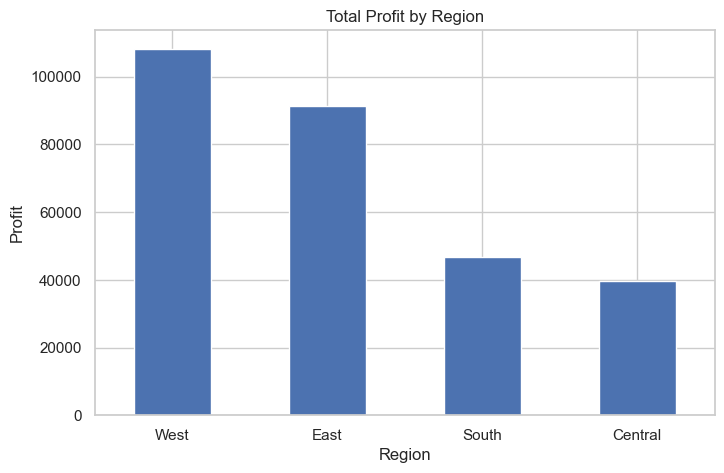

In [21]:
#Visualize the plot
region_profit=df.groupby('Region')['Profit'].sum().sort_values(ascending=False)
region_profit.plot(kind='bar',figsize=(8,5))
plt.title('Total Profit by Region')
plt.xlabel('Region')
plt.ylabel('Profit')
plt.xticks(rotation=0)
plt.show()

## Comapre Discount and Profit

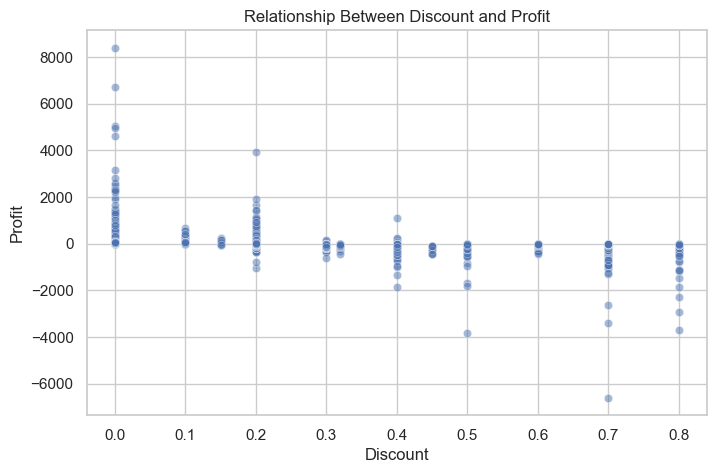

In [44]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df,x='Discount',y='Profit',alpha=0.5)
plt.title("Relationship Between Discount and Profit")
plt.xlabel('Discount')
plt.ylabel('Profit')
plt.show()

## Sales bu sub-Category

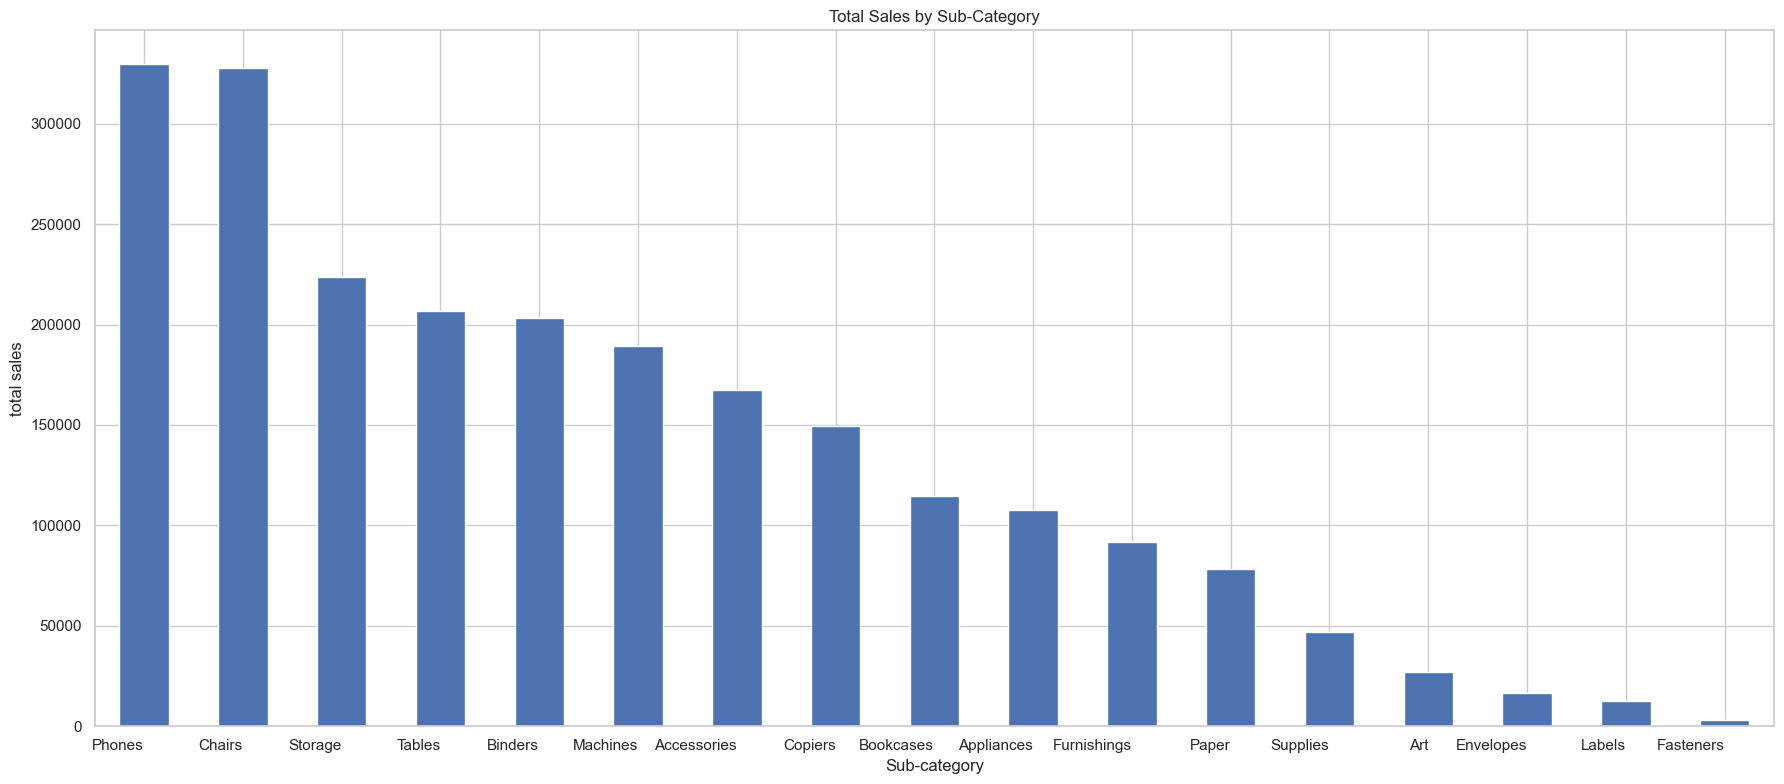

In [60]:
subcategory_sales=df.groupby('Sub-Category')['Sales'].sum().sort_values(ascending=False)
subcategory_sales.plot(kind="bar",figsize=(18,8))
plt.title("Total Sales by Sub-Category")
plt.xlabel("Sub-category")
plt.ylabel("total sales")
plt.xticks(rotation=0,ha="right")
plt.tight_layout()
plt.show()

## Profit by Product category

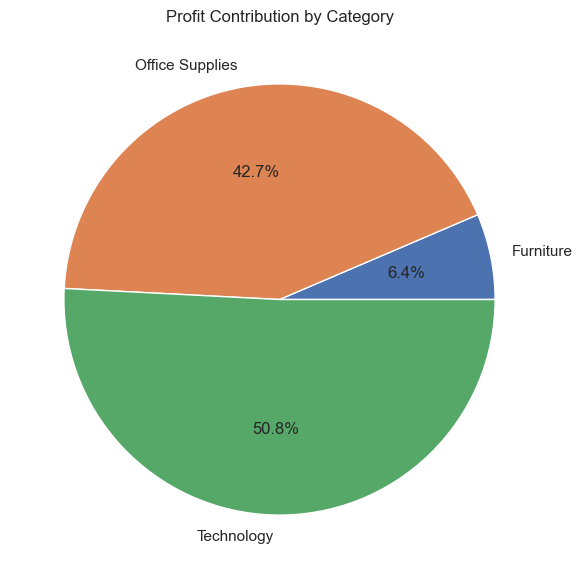

In [62]:
category_profit=df.groupby('Category')["Profit"].sum()
category_profit.plot(kind='pie',autopct="%1.1f%%",figsize=(7,7))
plt.title('Profit Contribution by Category')
plt.ylabel("")
plt.show()

## Sales by customer segment

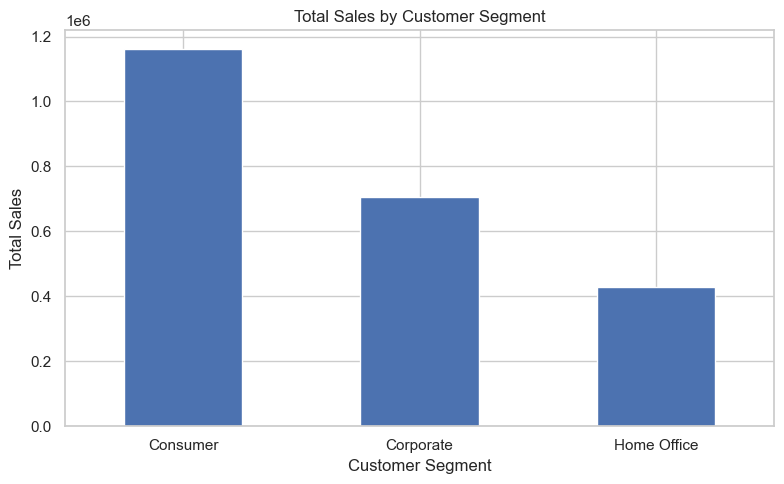

In [63]:
segment_sales=(df.groupby('Segment')['Sales'].sum().sort_values(ascending=False))
segment_sales.plot(kind="bar",figsize=(8,5))
plt.title("Total Sales by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Sales")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Find Top Five Business insights

In [67]:
print("Top 5 sub-categories by sales : ")
print(subcategory_sales.head(5))

Top 5 sub-categories by sales : 
Sub-Category
Phones     330007.054
Chairs     327777.761
Storage    223843.608
Tables     206965.532
Binders    203409.169
Name: Sales, dtype: float64


In [70]:
print("Profit by Category : ")
print(category_profit.sort_values(ascending=False))

Profit by Category : 
Category
Technology         145454.9481
Office Supplies    122364.6608
Furniture           18421.8137
Name: Profit, dtype: float64


In [74]:
print("Sales by Customer segment : ")
print(segment_sales)

Sales by Customer segment : 
Segment
Consumer       1.160833e+06
Corporate      7.060701e+05
Home Office    4.292927e+05
Name: Sales, dtype: float64


In [75]:
print("Profit by region : ")
print(region_profit)

Profit by region : 
Region
West       108329.8079
East        91506.3092
South       46749.4303
Central     39655.8752
Name: Profit, dtype: float64


In [76]:
print("Average profit by discount level : ")
print(df.groupby("Discount")['Profit'].mean().sort_index())

Average profit by discount level : 
Discount
0.00     67.024108
0.10     96.055074
0.15     27.288298
0.20     24.721217
0.30    -45.828401
0.32    -88.560656
0.40   -111.927429
0.45   -226.646464
0.50   -310.703456
0.60    -43.077212
0.70    -95.874060
0.80   -102.116395
Name: Profit, dtype: float64
